# DSS: normalized analytical eigenvalues and the three-peak ZQ spectrum

Analysis of the editorial letter and supplied molecule model · 18 October 2026

**Learned-model extension:** the companion [DSS ASN comparison](dss_asn_comparison.pdf) now contains actual training of the repository KharKAN/ASN, extracted network formulas, five-seed validation, and comparisons with this analytical reference and polynomial baselines. The present document supplies the physical derivation; its cubic and Taylor formulas are analytical references, not learned formulas.

**Result.** Retain the four-state parity block, all three distinct geminal couplings, and both nearest-neighbor coupling differences. For DSS, the small end-to-end difference can be omitted for a first spectrum at a linewidth of order 0.1 Hz. The fourth state can be weakly visible yet still shift the three principal lines appreciably. An exact cubic construction gives all four ordered eigenvalues, without deleting that state or fitting a neural network.

At the supplied DSS parameter point, the nearest-neighbor model predicts **3.708572, 4.666649, and 8.375221 Hz**. These are calculated line centers, not newly measured peak positions. Their sum relation is exact: the two adjacent gaps add to the outer gap.

## 1. What the editorial letter requires

`review.txt` is an editorial assessment inviting a revised submission. It identifies two separate shortcomings: a real-material/molecule NMR demonstration, and stronger literature context with comparisons to current methods. Adding DSS can address the first concern only if the paper connects eigenvalues to a measured observable, documents molecular parameters and approximations, and distinguishes predictions from experimental validation. The present analysis supplies that forward model, an exact analytical reference, sensitivity comparisons, and reproducible spectral sections.

The second concern includes a benchmarking task: adding references alone does not compare ASN performance. The existing manuscript already includes perturbative and polynomial baselines. The companion report now extends the actual ASN and polynomial comparisons to DSS. A relevant contemporary symbolic-regression baseline under the same data, tuning budget, and evaluation protocol is still needed. Section 10 gives concrete literature and comparison recommendations. No new PySR training or experimental refitting is claimed.

The manuscript's statement that ChatGPT was not used to generate research data will also need author review if these generated calculations or figures are incorporated. This is a factual consistency issue with the supplied manuscript, not an assessment of journal policy.

## 2. DSS parameters, experiment, and scope

The supplied `ASN_DSS_homotaurine_Hamiltonian.pdf` and `asn_three_ch2.py` give the following fitted DSS reference values, attributed there to a 31 July 2026 email and a 298 K fit. The underlying email and raw spectrum are not present in this folder.

| Parameter | Value / Hz | Meaning |
|---|---:|---|
| $J_A$ | −13.758727 | Geminal AA′ coupling |
| $J_M$ | −13.408159 | Geminal MM′ coupling |
| $J_X$ | −14.121958 | Geminal XX′ coupling |
| $d$ | 5.269170 | Full difference $J_{AM}-J_{AM'}$ |
| $e$ | 6.597217 | Full difference $J_{MX}-J_{MX'}$ |
| $q$ | 0.002490 | Optional full difference $J_{AX}-J_{AX'}$ |

The matrix elements are $d/2,e/2,q/2$. Confusing full and half differences changes the predicted spectrum substantially. Every Hamiltonian here is in Hz, so $U(\tau)=\exp(-i2\pi H\tau)$; diagonalization itself introduces no extra $2\pi$.

A primary-source search found the DSS three-component experiment in Fig. 8b of [Sheberstov, arXiv:2512.23759](https://arxiv.org/pdf/2512.23759). Its Methods report 298 K, a 500 MHz instrument, approximately 50 mM DSS in D₂O, poly-SLIC preparation on groups 1 and 2 with group 3 decoupled during preparation, RF-free evolution, a T₀₀ filter, and reconversion on group 1. The acquisition used 1024 evolution increments of 16.7 ms (approximately 17 s total). Thus the unpadded frequency-grid spacing is approximately 0.059 Hz. This supports the experiment class used here; it does not establish that the local 2026 fit belongs to that particular acquisition. The corresponding 2024 [JCP paper](https://doi.org/10.1063/5.0196808) reports ZQ linewidths of order 0.1 Hz. We use 0.1 Hz as an illustrative FWHM, not a newly fitted linewidth. A linewidth or Fourier-grid spacing does not impose an absolute limit on fitted line-center precision.

The supplied model assumes chemically equivalent protons within each CH₂ pair, isotropic intrapair couplings, secular interpair couplings, and no RF during evolution. It is exact within that reduced model. Pulse-sequence transfer efficiencies, relaxation, and the full isotropic six-proton correction are separate from the eigenvalue calculation.

## 3. Hamiltonian reduction: which terms can be omitted?

In the basis $(TSS,STS,SST,TTT)$, put $S_J=J_A+J_M+J_X$. The even-singlet-parity block is

$$H_+=-\frac{3S_J}{4}I+
\begin{pmatrix}
J_A&d/2&q/2&e/2\\
d/2&J_M&e/2&q/2\\
q/2&e/2&J_X&d/2\\
e/2&q/2&d/2&S_J
\end{pmatrix}.$$

The upper-left three-state block contains type-I transfer. The fourth row and column contain type-II mixing. The principal three levels are the upper three eigenvalues for the stated negative-geminal domain; the fourth, lower level is dominated by $TTT$.

**Terms that vanish in the specified subspace.** Let $L_{i,z}=I_{i,z}+I_{i',z}$ and $D_{i,z}=I_{i,z}-I_{i',z}$. Both $S$ and $T_0$ have $L_{i,z}=0$. Under the pairwise coupling symmetries in the supplied model, the interpair secular term is

$$\bar J_{ij}L_{i,z}L_{j,z}+\frac{\Delta J_{ij}}{2}D_{i,z}D_{j,z},\qquad
\bar J_{ij}=\frac{J_{ij}+J_{ij'}}{2}.$$

Consequently, the common chemical-shift terms and the mean interpair secular couplings vanish exactly on the product $\{S,T_0\}$ subspace. A global identity term can also be removed because only energy differences enter the spectrum. This does not justify neglecting chemical-shift differences between the CH₂ groups when assessing the high-field secular approximation: those differences suppress the discarded interpair flip-flops.

**Terms requiring an error comparison.** Interpair nonsecular terms connect the retained states to other six-spin states. Their effects depend on the actual chemical-shift separations and individual couplings, which the five supplied parameters do not specify. They cannot be quantitatively certified negligible at millihertz accuracy from these files alone. Keep the secular model as an explicit assumption.

The calculated DSS error budget is:

| Model | f12 / Hz | f23 / Hz | f13 / Hz | Max. error vs q=0 / Hz |
|---|---:|---:|---:|---:|
| exact nearest-neighbor | 3.708572 | 4.666649 | 8.375221 | 0.000000 |
| drop type-II (bare 3x3) | 4.030434 | 4.439583 | 8.470017 | 0.321861 |
| second-order effective 3x3 | 3.700146 | 4.671773 | 8.371920 | 0.008426 |
| replace geminals by their mean | 3.912987 | 4.464699 | 8.377686 | 0.204415 |
| include q, even parity | 3.707014 | 4.668631 | 8.375644 | 0.001982 |
| include q, odd parity (matched) | 3.710131 | 4.664667 | 8.374798 | 0.001982 |


The reference for these errors is the full four-state *nearest-neighbor secular block*, not a measured spectrum. Setting all geminals to their mean produces a maximum line error of 0.204415 Hz. Deleting type-II mixing produces 0.321861 Hz. Both exceed the illustrative linewidth and are inappropriate for the proposed DSS application. In contrast, omitting fitted $q$ changes each parity's principal lines by at most 0.001982 Hz at this point. The two parity blocks can differ by up to 0.003964 Hz when $q$ is retained. They will normally overlap at a 0.1 Hz linewidth, but $q$ should be included for millihertz line-center fitting.

The amplitude of a missing line is not a measure of the associated virtual energy shift. Here the $TTT$ probabilities in the three principal eigenstates are approximately 1.40%, 0.12%, and 0.84%, yet the line shifts from omitting that state reach 0.322 Hz.

For a controlled three-state approximation, write $H=\begin{pmatrix}A&v\\v^T&b\end{pmatrix}$. Eliminating the fourth component gives the exact energy-dependent equation

$$\left[A+\frac{vv^T}{E-b}\right]\psi=E\psi.$$

Thus the omitted state leaves a self-energy even when it is not directly detected. In an eigenbasis $A|i\rangle=a_i|i\rangle$, a Hermitian second-order approximation is

$$ (H_{\mathrm{eff}})_{ij}=a_i\delta_{ij}+
\frac{v_i v_j}{2}\left(\frac{1}{a_i-b}+\frac{1}{a_j-b}\right).$$

Retain its induced off-diagonal elements and diagonalize the effective matrix. This gives a maximum DSS line error of 0.008426 Hz. It is a useful compact baseline, although the exact construction below is preferable and inexpensive. The expansion requires separation from $b$; it does not require separation between the $a_i$.

## 4. Normalize five physical parameters to four inputs

Use the supplied positive scale and energy reference:

$$s=-J_M>0,\qquad E_{\mathrm{ref}}=\frac{-3J_A+J_M-3J_X}{4},$$

$$x_A=\frac{J_A-J_M}{s},\quad x_X=\frac{J_X-J_M}{s},\quad
u=\frac{d}{s},\quad v=\frac{e}{s}.$$

For $q=0$,

$$H_+=E_{\mathrm{ref}}I+sK,\qquad
K=\begin{pmatrix}
x_A&u/2&0&v/2\\
u/2&0&v/2&0\\
0&v/2&x_X&u/2\\
v/2&0&u/2&-2+x_A+x_X
\end{pmatrix}.$$

The energies and frequencies recover their physical dimensions as $E_i=E_{\mathrm{ref}}+s\lambda_i$ and $f_{ij}=s|\lambda_i-\lambda_j|$. Scaling all couplings by a common positive factor scales every frequency by that factor and leaves the inputs unchanged. Subtracting a reference simplifies the algebra; it does not remove a further independent physical parameter. If $q$ is variable, add $q/s$ as a fifth input.

For DSS,

$$s=13.408159\ \mathrm{Hz},\quad E_{\mathrm{ref}}=17.558474\ \mathrm{Hz},$$

$$(x_A,x_X,u,v)=(-0.0261458713,-0.0532361676,0.3929823625,0.4920300393).$$

## 5. Exact analytical solution retaining type-II mixing

Define $h_A=J_A/s=x_A-1$, $h_X=J_X/s=x_X-1$, and the dimensionless bidiagonal matrix

$$B=\begin{pmatrix}h_A&u&0\\0&-1&v\\0&0&h_X\end{pmatrix}.$$

Let $z_1\le z_2\le z_3$ be the eigenvalues of $BB^T$, and set $\omega_k=s\sqrt{z_k}$. These are positive normal-mode energies. This construction is consistent with the quadratic-fermion structure of the open transverse-field Ising chain; see [Dutta et al., exact-solution review](https://arxiv.org/abs/1012.0653). A direct polynomial proof below establishes the identity for this particular molecular block without requiring that mapping.

The three squared modes are the roots of

$$z^3-C_1z^2+C_2z-C_3=0,$$

$$C_1=h_A^2+1+h_X^2+u^2+v^2,$$

$$C_2=h_A^2+h_A^2h_X^2+h_X^2+h_A^2v^2+h_X^2u^2+u^2v^2,\qquad
C_3=h_A^2h_X^2.$$

An explicit real-root formula is obtained by setting

$$\mu=\frac{C_1}{3},\quad R=\frac{\sqrt{C_1^2-3C_2}}{3},\quad
\theta=\frac13\arccos\!\left(\frac{2C_1^3-9C_1C_2+27C_3}{2(C_1^2-3C_2)^{3/2}}\right).$$

$$z_1=\mu+2R\cos(\theta+2\pi/3),\quad
z_2=\mu+2R\cos(\theta-2\pi/3),\quad
z_3=\mu+2R\cos\theta.$$

Here $0\le\theta\le\pi/3$, which fixes the root ordering. If $R=0$, all three roots are $\mu$. In floating-point evaluation, compute centered matrix invariants to avoid cancellation, clip the arccos argument, and use a symmetric eigensolver very close to a repeated root. The implementation documents this numerical fallback; it does not change the analytical solution.

Put $c_0=-S_J/4$. For three negative geminals, the four even-block eigenvalues are exactly

$$E_0=c_0-\frac{\omega_1+\omega_2+\omega_3}{2},$$
$$E_1=c_0+\frac{\omega_1+\omega_2-\omega_3}{2},$$
$$E_2=c_0+\frac{\omega_1-\omega_2+\omega_3}{2},$$
$$E_3=c_0+\frac{-\omega_1+\omega_2+\omega_3}{2}.$$

These automatically obey $E_0<E_1\le E_2\le E_3$. Therefore the principal transition frequencies are

$$\boxed{f_{12}=\omega_3-\omega_2,\qquad
f_{23}=\omega_2-\omega_1,\qquad
f_{13}=\omega_3-\omega_1=f_{12}+f_{23}.}$$

**Algebraic proof.** In physical units define $\mathcal C_1=J_A^2+J_M^2+J_X^2+d^2+e^2$, $\mathcal C_2=J_A^2J_M^2+J_A^2J_X^2+J_M^2J_X^2+J_A^2e^2+J_X^2d^2+d^2e^2$, and $\mathcal C_3=(J_AJ_MJ_X)^2$. The characteristic polynomial of $H_+-c_0I$, with spectral variable $\epsilon$, is

$$\epsilon^4-\frac{\mathcal C_1}{2}\epsilon^2-J_AJ_MJ_X\epsilon+
\frac{\mathcal C_1^2-4\mathcal C_2}{16}.$$

The squared modes have sum $\mathcal C_1$, pair-product sum $\mathcal C_2$, and product $\mathcal C_3$. Multiplying the four factors associated with the sign combinations above gives this quartic, because $\omega_1\omega_2\omega_3=|J_AJ_MJ_X|=-J_AJ_MJ_X$. Both polynomial identities are checked exactly with SymPy in the supplied tests. This proof retains all type-II matrix elements; the formula is not valid unchanged for nonzero $q$ or arbitrary geminal signs.

## 6. Labels at crossings and touches

The manuscript, Sec. IV.B, explicitly switched to fixed ordered eigenvalue surfaces after continuation of signed perturbative branches caused jumps in two dimensions. Follow that convention. The manuscript's descending $E/J_{\mathrm{intra}}$ corresponds to ascending physical $E$, because its scale is negative. Here $s>0$, so sort both $E$ and $\lambda$ in ascending order. Our zero-based indices $(0,1,2,3)$ correspond to the paper's physical-energy labels $(1,2,3,4)$.

At a genuine degeneracy the ordered surfaces remain continuous but may have cusps. There is no globally smooth, unique eigenvector identity at a degenerate point. At an avoided crossing the energy branches stay ordered while state character may exchange. Do not swap regression outputs in an attempt to preserve basis-state character. For eigenvector-dependent observables, use spectral projectors; at exact degeneracy aggregate the whole degenerate subspace and equal-frequency contributions.

Positive $d,e$ and nonzero geminals make $BB^T$ an irreducible real symmetric tridiagonal matrix, so its eigenvalues are simple in the interior. Exact touches can occur on decoupled boundaries. Coupling-sign changes can be removed by basis phases for the open nearest-neighbor chain, and the ordered energy surfaces depend on $d^2,e^2$.

The line labels need separate care: retain $f_{12}$ and $f_{23}$ by their energy-level indices even if their *frequencies* cross. Sorting those two gaps into “small” and “middle” at every point exchanges transition identities. The original utility sorts frequency magnitudes for presentation; the new analysis exports stable `f12`, `f23`, `f13` columns instead. Also retain all four energies: a positive-energy filter is not invariant under a reference shift.

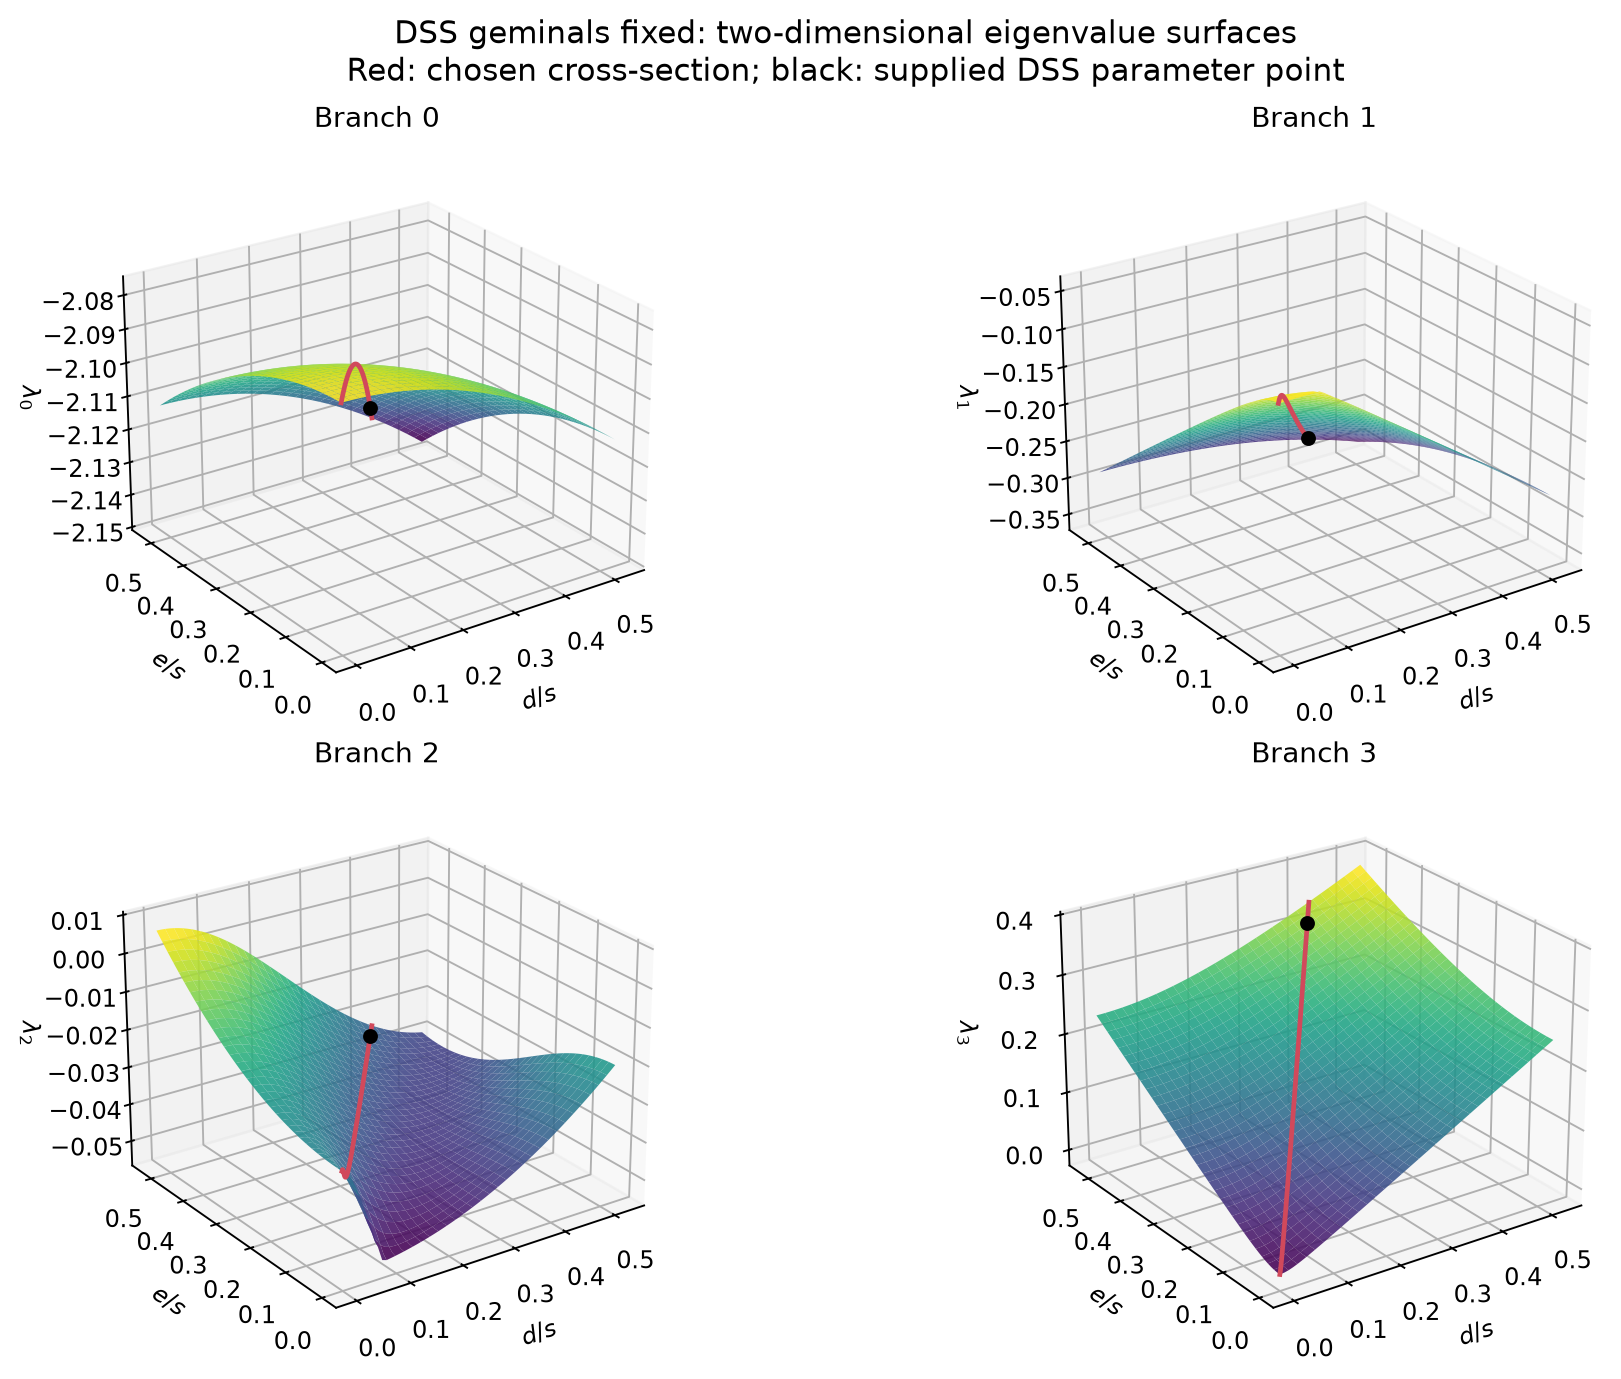

## 7. DSS cross-section and its analytical description

Fix all three geminals at the DSS fit and scale the two nearest-neighbor differences together:

$$d(t)=5.269170t,\qquad e(t)=6.597217t\quad\mathrm{Hz}.$$

Equivalently, $x_A,x_X$ are fixed and $(u,v)=t(u_*,v_*)$, with $v/u=1.252041024$. The fitted molecule is $t=1$. This is a defined mathematical section through the four-input model; no temperature or chemical dependence of $t$ is assumed. The plot extends to $t=1.5$ to expose curvature. Its portion above approximately $t=1.06105$ lies outside the supplied initial $e\le7$ Hz training box; the exact Hamiltonian remains well-defined there.

On this section the entire analytical dependence reduces to

$$C_1(t)=3.162281774033+0.396528696796t^2,$$
$$C_2(t)=3.330354094093+0.426234440375t^2+0.037387752092t^4,$$
$$C_3(t)=1.168072320061.$$

Substitute these into the ordered cubic-root formula, take the positive square roots, and form the energies or three gaps above. This is an explicit analytical description on the chosen section, valid beyond a local Taylor expansion. Rounded coefficients here are for display; calculations use the full supplied coupling precision.

At $t=1$,

$$ (\omega_1,\omega_2,\omega_3)=(9.848639699,14.515288616,18.223861043)\ \mathrm{Hz},$$

$$ (E_0,E_1,E_2,E_3)=(-10.971683679,13.392244636,17.100817063,21.767465980)\ \mathrm{Hz},$$

$$ (\lambda_0,\lambda_1,\lambda_2,\lambda_3)=(-2.127820656,-0.310723446,-0.034132720,0.313912744).$$

For a compact local polynomial, write $\delta=t-1$. Analytic differentiation, rather than a regression fit, gives

$$f_{12}(t)=3.708572427+3.543282897\delta-0.346209425\delta^2+O(\delta^3)\quad\mathrm{Hz}.$$

$$f_{23}(t)=4.666648917+4.651738187\delta+0.191450185\delta^2+O(\delta^3)\quad\mathrm{Hz}.$$

$$f_{13}(t)=8.375221344+8.195021084\delta-0.154759240\delta^2+O(\delta^3)\quad\mathrm{Hz}.$$

The maximum absolute error of these quadratic expressions on a 401-point check over $0.9\le t\le1.1$ is **0.000080 Hz** across the three lines (using unrounded coefficients). The reported value is a sampled validation, not a rigorous uniform error bound. Their sum relation is enforced exactly before rounding. These coefficients are suitable local references for a learned expression; they are not ASN results.

For reproducibility, with $M(t)=B(t)B(t)^T$, its normalized eigenvectors $w_k$, and nondegenerate squared modes $z_k$,

$$z'_k=w_k^TM'w_k,\qquad
z''_k=w_k^TM''w_k+2\sum_{l\ne k}\frac{|w_l^TM'w_k|^2}{z_k-z_l},$$

$$\omega'_k=\frac{s z'_k}{2\sqrt{z_k}},\qquad
\omega''_k=s\left(\frac{z''_k}{2\sqrt{z_k}}-\frac{(z'_k)^2}{4z_k^{3/2}}\right).$$

Differencing these derivatives in the same order as the frequencies gives the polynomial coefficients. Do not use this derivative formula at a repeated $z_k$.

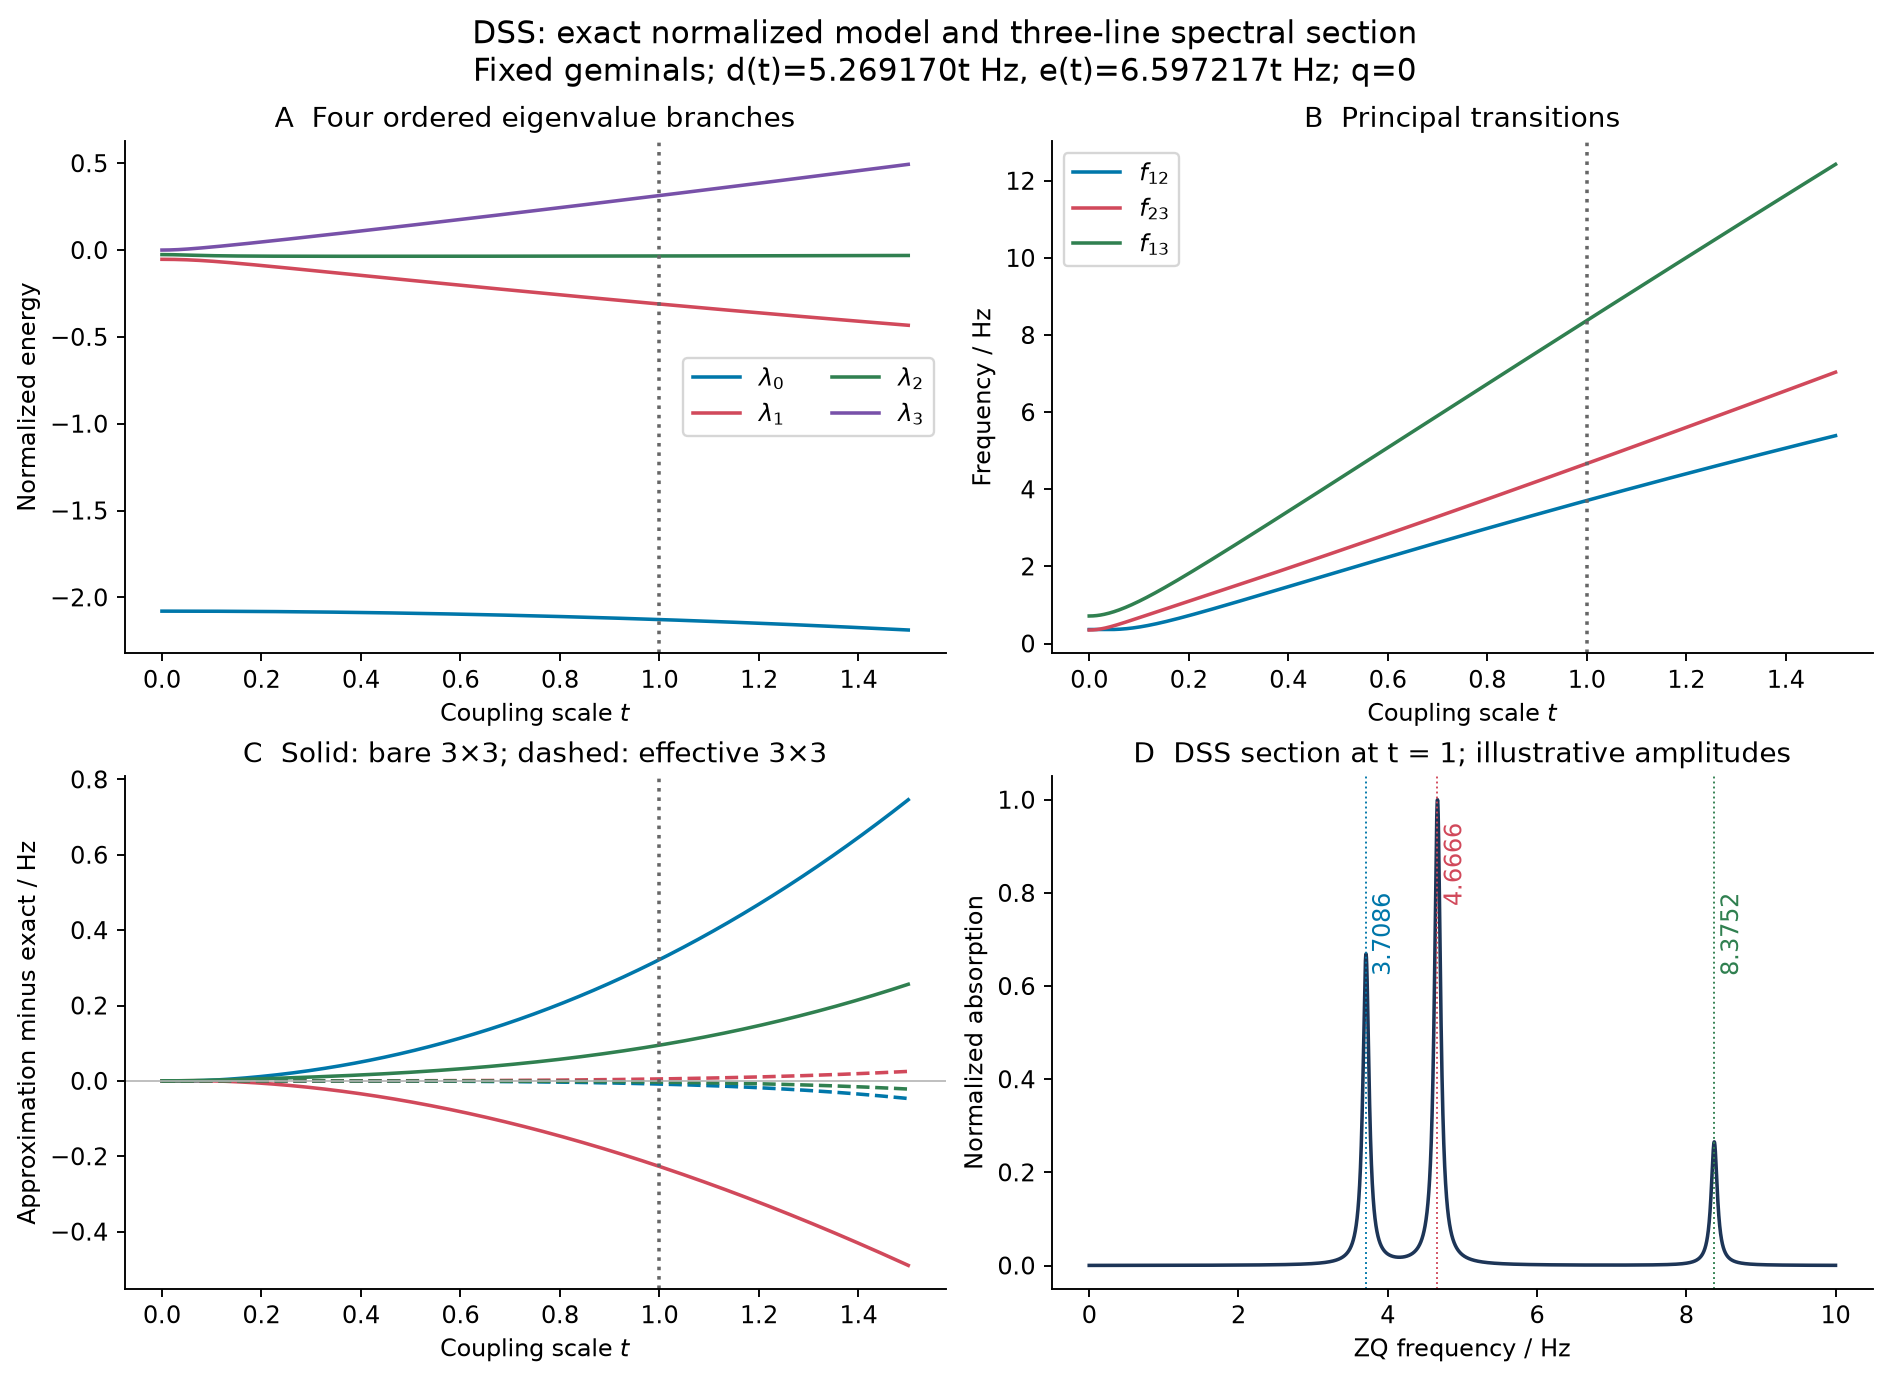

## 8. From energy gaps to an observable spectrum

The general measured evolution is

$$S(\tau)=\mathrm{Tr}\left[Oe^{-i2\pi H\tau}\rho_0e^{i2\pi H\tau}\right].$$

In the energy basis, the pair $(i,j)$ contributes

$$2\operatorname{Re}(Z_{ij})\cos(2\pi f_{ij}\tau)-2\operatorname{Im}(Z_{ij})\sin(2\pi f_{ij}\tau),\qquad
Z_{ij}=(\rho_0)_{ij}O_{ji}.$$

Thus eigenvalues determine candidate positions; the preparation, readout, and relaxation determine which peaks appear. Exact algebraic expressions for amplitudes are available without choosing eigenvector phases: for simple levels,

$$P_i=\prod_{j\ne i}\frac{H-E_jI}{E_i-E_j},\qquad
Z_{ij}=\mathrm{Tr}(O P_i\rho_0 P_j).$$

At degeneracy use the combined spectral projector. This avoids undefined eigenvector-based labels.

For the displayed spectrum we explicitly choose an illustrative local singlet autocorrelation on the A pair: $\rho_0=O=P_{S,A}-I/2=\mathrm{diag}(-1/2,1/2,1/2,-1/2)$ in the even block. This is a traceless deviation operator, not a normalized positive density matrix. The arbitrary signal normalization is $\mathrm{Tr}(O^2)=1$. This choice is not a reconstruction of the published poly-SLIC preparation, filter, or reconversion efficiencies.

For this observable, the principal cosine amplitudes at $t=1$ are:

| Transition | Frequency / Hz | Cosine amplitude |
|---|---:|---:|
| $E_2-E_1$ | 3.708572 | 0.186844 |
| $E_3-E_2$ | 4.666649 | 0.279865 |
| $E_3-E_1$ | 8.375221 | 0.074383 |

The plotted positive-frequency absorption section uses

$$I(\nu;t)=\sum_{(ij)=(12),(23),(13)} A_{ij}(t)
\frac{\Gamma/(2\pi)}{[\nu-f_{ij}(t)]^2+(\Gamma/2)^2},\qquad\Gamma=0.1\ \mathrm{Hz}.$$

Each Lorentzian has area $A_{ij}$; DC, negative-frequency partners, and dispersive terms are excluded from this display convention. The implemented low-frequency plot also retains the very small tails of the three higher-frequency lines. Their centers are $\omega_1+\omega_2$, $\omega_1+\omega_3$, and $\omega_2+\omega_3$: 24.363928, 28.072501, and 32.739150 Hz, with cosine amplitudes 0.010268, 0.006621, and 0.002397 for this illustrative readout. They are weaker, not identically forbidden. The presence of only three experimentally reported low-frequency peaks is therefore compatible with the four-state model; it does not prove all other transitions vanish. In an actual sampled experiment, aliasing, acquisition bandwidth, filtering, and relaxation also matter. No finite-time Fourier transform or pulse-sequence simulation is claimed by the Lorentzian plot.

For $q=0$ the odd block obeys $H_-=-D H_+D-S_JI/2$, $D=\mathrm{diag}(1,-1,1,-1)$, so the principal line positions coincide between parity sectors. Nonzero $q$ breaks that equality. The comparison plot uses equal parity weights only as an illustration. A quantitative intensity fit requires the actual prepared density operators and the effective detection operator after filtering/reconversion.

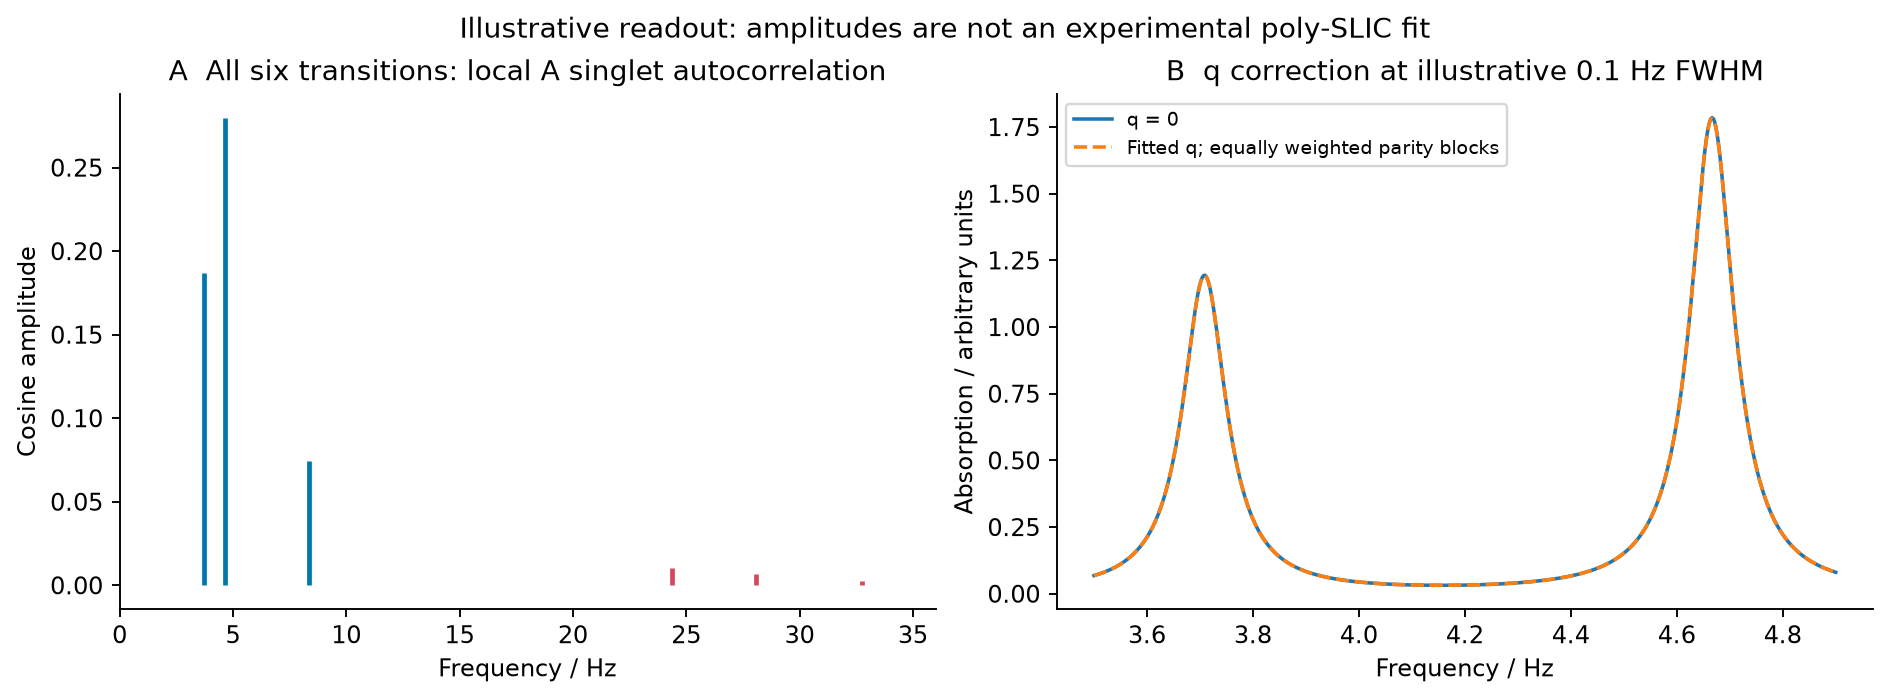

Only two of the three principal frequencies are independent. A single three-line spectrum therefore cannot identify all five Hamiltonian parameters. Test the experimental relation $f_{\mathrm{outer}}=f_{\mathrm{adjacent},1}+f_{\mathrm{adjacent},2}$ within uncertainties, and use conventional spectra, independent couplings, or additional conditions to constrain an inverse fit.

## 9. Validation and limits of the present result

The supplied six-spin coefficient projection checks still pass. Additional tests compare the cubic solution with the independent 4×4 Hamiltonian at 2,000 random signed-coupling points; cover zero couplings, double/triple degeneracies, scaling, energy-reference reconstruction, parity relations, and continuity through a signed uniform-chain crossing; reconstruct real signals for arbitrary complex Hermitian preparation/readout operators; and verify the local analytic derivatives. Three exact symbolic identities prove the mode cubic, the centered molecular quartic, and the sign-combination factorization. All **11 tests pass** in the temporary analysis environment.

The new deliverables provide an exact forward solution of the supplied secular nearest-neighbor model and an illustrative observable spectrum. They do not establish agreement with digitized experimental DSS line centers or intensities. The complete fitted chemical shifts and individual interpair couplings, raw time-domain data, relaxation constants, and effective pulse-sequence preparation/readout operators were not supplied. Published protocol information is recorded above, but it does not fill those numerical gaps. The local homotaurine reference was also evaluated in the CSV/JSON output; its unresolved temperature/provenance issue remains as documented in the supplied PDF, and it is not the main example selected by the user.

For an ASN dataset, sample physical couplings first, then normalize. Use all four ordered $\lambda_i$ or clearly identified principal targets, and preserve the fixed frequency labels. The exact constraints are $\sum_i\lambda_i=2(x_A+x_X)-2$ and $f_{13}=f_{12}+f_{23}$. Test near decoupled boundaries separately. Report eigenvalue errors and frequency errors in Hz; an eigenvalue error bound of $\varepsilon$ only guarantees a gap error of at most $2\varepsilon$. With the cubic solution now available, it should be included as an exact reference and timing baseline rather than presented as a learned formula.

## 10. Literature context and the comparison still needed for resubmission

The following primary sources support a focused extension of the discussion:

| Source | Relevance to the revision |
|---|---|
| [Sahoo, Lampert & Martius, EQL (2018)](https://proceedings.mlr.press/v80/sahoo18a.html) | Differentiable equation learning with predefined operators; already cited, but compare the actual construction and selection mechanism. |
| [Udrescu & Tegmark, AI Feynman (2020)](https://arxiv.org/abs/1905.11481) | Physics-informed symbolic discovery and dimensional reduction; relevant precedent for the normalization step. |
| [Udrescu et al., AI Feynman 2.0 (2020)](https://arxiv.org/abs/2006.10782) | Accuracy–complexity tradeoffs, modularity, and robustness; a useful methodological contrast. |
| [La Cava et al., SRBench (2021)](https://arxiv.org/abs/2107.14351) | Reproducible comparisons across methods and datasets; supports a common evaluation protocol. |
| [Cranmer, PySR (2023)](https://arxiv.org/abs/2305.01582) | A practical evolutionary symbolic-regression baseline with explicit expressions. |
| [Aldeia et al., updated SRBench (2025)](https://arxiv.org/abs/2505.03977) | Current benchmark context, compute budgets, and complexity/accuracy tradeoffs; avoids relying only on older comparisons. |
| [Dutta et al., transverse-field models (2010)](https://arxiv.org/abs/1012.0653) | Exact solvability context for the open-chain Hamiltonian and the normal-mode construction. |
| [Sheberstov et al., JCP (2024)](https://doi.org/10.1063/5.0196808) and [Sheberstov preprint (2025)](https://arxiv.org/abs/2512.23759) | Molecular ZQ observables and the demonstrated DSS experiment; already related to the manuscript's physical motivation. |

A concrete comparison should use the exact normalized DSS model on the same training/validation/test splits for ASN, fixed-degree polynomial least squares, and at least PySR or another well-motivated current symbolic method. Keep the exact cubic and second-order effective Hamiltonian as physics references. Include both a matched polynomial-operator comparison and, separately, a richer-operator comparison if square roots are permitted. Restrict extrapolation claims to independently tested domains.

Match data availability and tuning/computational budgets; run several seeds; report test RMSE and worst-case error for energies and line positions, expression size after simplification, training time, evaluation time, ordering violations, sum-rule violations, and errors near boundaries. Hold out molecular neighborhoods or sections as well as random points to expose interpolation leakage. The companion report now supplies five-seed ASN training, quadratic/quartic least-squares baselines, and independent sections and boundary evaluations. Comparisons with external contemporary symbolic-regression methods remain to be performed. The analytical model alone does not resolve that editorial request.

Suggested manuscript claim, supported by this work: *For DSS with three distinct geminal couplings, a four-input dimensionless Hamiltonian predicts three principal zero-quantum line positions. An exact cubic reference retains the virtual effect of an additional state and enables controlled assessment of learned and perturbative approximations in directly observable frequency units.* Avoid claiming that three peaks imply a three-dimensional Hamiltonian, that the fitted couplings have been independently validated here, or that ASN outperforms the exact solution or untested baselines.

## 11. Files and reproduction

- `real_molecule_analysis.py`: exact normalized solution, transition amplitudes, controlled effective model, analytic derivatives, CSV/JSON export, and figures.
- `test_real_molecule_analysis.py`: numerical and symbolic verification.
- `analysis_output/dss_cross_section.{pdf,svg,png}`: four ordered energies, three frequencies, truncation errors, and spectral section.
- `analysis_output/dss_eigenvalue_surfaces.{pdf,svg,png}`: two-dimensional section at fixed DSS geminals.
- `analysis_output/dss_observability.{pdf,svg,png}`: all six candidate transitions and parity/q correction.
- `analysis_output/dss_cross_section.csv`, `dss_eigenvalue_surface.csv`, `dss_illustrative_spectrum.csv`, `model_comparison.csv`, `illustrative_transition_amplitudes.csv`, and `results.json`: calculated numerical data.

From the repository root:

```bash
python ANSWER/real_molecule_analysis.py --figures
python -m unittest discover -s ANSWER -p 'test_real_molecule_analysis.py' -v
python ANSWER/build_dss_report.py
```

Core calculations need NumPy. Figures add Matplotlib; exact symbolic checks add SymPy. Report building adds `markdown` and `latex2mathml`. The analysis run used an isolated environment at `/tmp/nmrkan-analysis-venv`; no project dependency files were changed. Original supplied files remain intact. The HTML embeds figures and MathML for offline reading, and the notebook retains editable mathematical text and runnable example cells.

In [ ]:
from pathlib import Path
import sys
import numpy as np
folder = Path.cwd() if (Path.cwd() / 'real_molecule_analysis.py').exists() else Path.cwd() / 'ANSWER'
sys.path.insert(0, str(folder))
from real_molecule_analysis import *
p = np.array(EXAMPLES[next(iter(EXAMPLES))]['parameters'])
print('Ordered energies / Hz:', analytical_eigenvalues(p))
print('f12, f23, f13 / Hz:', analytical_frequencies(p))
print('Taylor coefficients:', cross_section_taylor(p))


In [ ]:
# All transition frequencies and amplitudes for a specified observable.
O = singlet_observable('A')
dc, lines = spectral_lines(hamiltonian(*p), O, O)
print('DC:', dc)
for line in lines:
    print(line)
